# 07 — Action Chunking with Transformers (ACT)

## Learning objectives

In previous notebooks, we implemented conditional generative
policies using MDNs, CVAEs, Diffusion Models and Flow Matching.

We now study **Action Chunking with Transformers (ACT)**.

ACT combines:

- Action chunking for predicting multiple future actions.
- Transformers for modeling structured action sequences.
- A conditional variational autoencoder for learning multimodal behavior.
- Temporal ensembling for smoothing overlapping predictions.

Our goal is to implement a simplified version of ACT from scratch
and understand how its components relate to our previous Chunk CVAE.

We will initially use the PointRobot environment before moving
to standard manipulation benchmarks such as PushT.

## 1. Self-Attention

A Transformer processes a sequence of tokens and learns
relationships between them.

For each token, three vectors are computed:

- Query (Q): what information the token is looking for.
- Key (K): what information each token provides for matching.
- Value (V): the information that will be aggregated.

Scaled dot-product attention is defined as:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

Unlike an MLP operating on a flattened chunk, self-attention
explicitly computes interactions between token positions.

We begin with a small numerical example before introducing
learnable projections and multi-head attention.

In [1]:
import math
import torch
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Four tokens, each represented by a 3D feature vector
X = torch.tensor([
    [1.0, 0.0, 0.0],
    [0.9, 0.1, 0.0],
    [0.0, 1.0, 0.0],
    [0.0, 0.9, 0.1],
])

# Identity projections for this first example
Q = X
K = X
V = X

d_k = K.shape[-1]

scores = Q @ K.T / math.sqrt(d_k)
weights = torch.softmax(scores, dim=-1)

output = weights @ V

print("Input shape:", X.shape)
print("Attention matrix shape:", weights.shape)
print("Output shape:", output.shape)
print("\nAttention weights:\n", weights)

Input shape: torch.Size([4, 3])
Attention matrix shape: torch.Size([4, 4])
Output shape: torch.Size([4, 3])

Attention weights:
 tensor([[0.3261, 0.3078, 0.1831, 0.1831],
        [0.3114, 0.2973, 0.1962, 0.1951],
        [0.1811, 0.1919, 0.3226, 0.3045],
        [0.1873, 0.1972, 0.3149, 0.3006]])


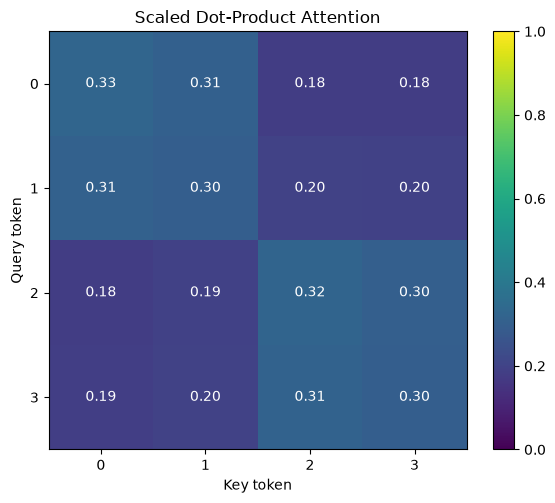

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
    weights.numpy(),
    cmap="viridis",
    vmin=0,
    vmax=1,
)

for i in range(4):
    for j in range(4):
        ax.text(
            j, i,
            f"{weights[i, j]:.2f}",
            ha="center",
            va="center",
            color="white",
        )

ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xlabel("Key token")
ax.set_ylabel("Query token")
ax.set_title("Scaled Dot-Product Attention")

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### 1.2 Learnable Multi-Head Attention

In the previous example, queries, keys and values were identical
to the input tokens.

A Transformer instead learns three linear projections:

$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V
$$

Multi-Head Attention computes attention in multiple learned
representation subspaces.

For each head:

$$
\operatorname{head}_i =
\operatorname{softmax}
\left(\frac{Q_iK_i^\top}{\sqrt{d_k}}\right)V_i
$$

The outputs are concatenated and projected:

$$
\operatorname{MHA}(X)=
\operatorname{Concat}(\operatorname{head}_1,\ldots,\operatorname{head}_h)W_O
$$

Different attention heads can learn different relationships
between tokens.

We will first inspect the output and attention weights of
a randomly initialized Multi-Head Attention layer.

In [3]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Sequence configuration
batch_size = 1
seq_len = 8
d_model = 32
n_heads = 4

# Eight tokens with 32 features each
X = torch.randn(batch_size, seq_len, d_model)

attention = nn.MultiheadAttention(
    embed_dim=d_model,
    num_heads=n_heads,
    batch_first=True,
)

Y, attention_weights = attention(
    query=X,
    key=X,
    value=X,
    need_weights=True,
    average_attn_weights=False,
)

print("Input:", X.shape)
print("Output:", Y.shape)
print("Attention weights:", attention_weights.shape)

Input: torch.Size([1, 8, 32])
Output: torch.Size([1, 8, 32])
Attention weights: torch.Size([1, 4, 8, 8])


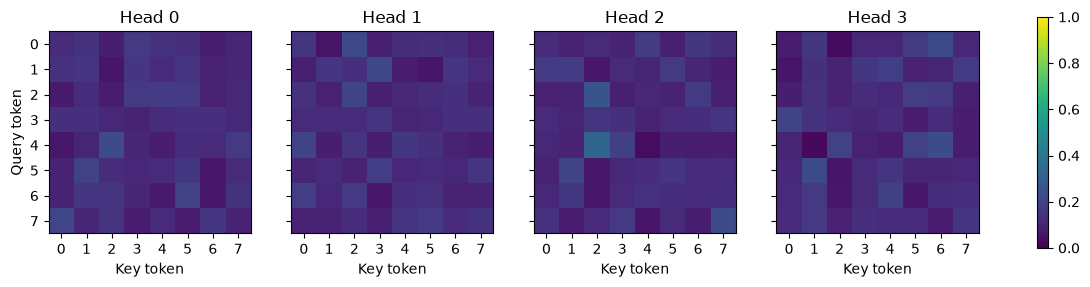

In [4]:
fig, axes = plt.subplots(
    1, n_heads,
    figsize=(15, 4),
    sharex=True,
    sharey=True,
)

for head_idx, ax in enumerate(axes):

    weights = attention_weights[
        0, head_idx
    ].detach().numpy()

    im = ax.imshow(
        weights,
        cmap="viridis",
        vmin=0,
        vmax=1,
    )

    ax.set_title(f"Head {head_idx}")
    ax.set_xlabel("Key token")
    ax.set_xticks(range(seq_len))
    ax.set_yticks(range(seq_len))

axes[0].set_ylabel("Query token")

fig.colorbar(
    im,
    ax=axes,
    shrink=0.75,
)

plt.show()

### 1.3 Cross-Attention

Self-attention uses queries, keys and values from the same sequence.

Cross-attention uses queries from one sequence and keys/values
from another:

$$
Q=X_{\text{query}}W_Q
$$

$$
K=X_{\text{context}}W_K,\qquad
V=X_{\text{context}}W_V
$$

The attention operation is:

$$
\operatorname{CrossAttention}(Q,K,V)
=
\operatorname{softmax}
\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

In ACT, the Transformer decoder uses action queries to retrieve
information from the encoded observation context.

The decoder can therefore generate action representations
conditioned on the robot state, latent variables and visual features.

In [5]:
torch.manual_seed(42)

batch_size = 1
n_queries = 8
n_context = 3
d_model = 32
n_heads = 4

# Future action positions
action_queries = torch.randn(
    batch_size, n_queries, d_model
)

# Encoded context: e.g. robot state, latent, vision
context = torch.randn(
    batch_size, n_context, d_model
)

cross_attention = nn.MultiheadAttention(
    embed_dim=d_model,
    num_heads=n_heads,
    batch_first=True,
)

output, cross_weights = cross_attention(
    query=action_queries,
    key=context,
    value=context,
    average_attn_weights=False,
)

print("Queries:", action_queries.shape)
print("Context:", context.shape)
print("Output:", output.shape)
print("Cross-attention:", cross_weights.shape)

Queries: torch.Size([1, 8, 32])
Context: torch.Size([1, 3, 32])
Output: torch.Size([1, 8, 32])
Cross-attention: torch.Size([1, 4, 8, 3])


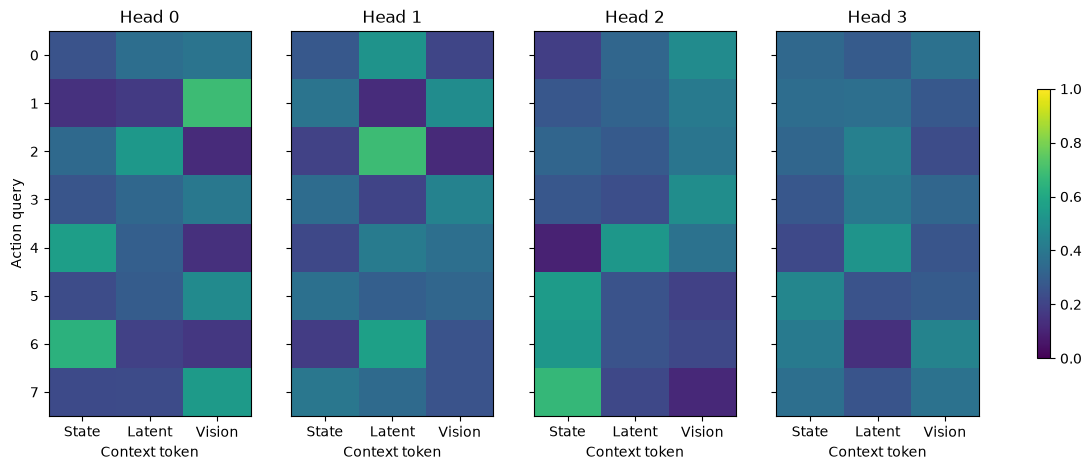

In [6]:
fig, axes = plt.subplots(
    1, n_heads,
    figsize=(15, 5),
    sharey=True,
)

for head_idx, ax in enumerate(axes):

    weights = cross_weights[
        0, head_idx
    ].detach().numpy()

    im = ax.imshow(
        weights,
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="auto",
    )

    ax.set_title(f"Head {head_idx}")
    ax.set_xlabel("Context token")

    ax.set_xticks(range(n_context))
    ax.set_xticklabels(["State", "Latent", "Vision"])

    ax.set_yticks(range(n_queries))

axes[0].set_ylabel("Action query")

fig.colorbar(im, ax=axes, shrink=0.7)
plt.show()

## 2. Transformer Decoder Block

We now combine self-attention, cross-attention and a feed-forward
network into a Transformer decoder block.

The block contains three sublayers:

1. Self-attention between action queries.
2. Cross-attention between action queries and observation tokens.
3. A position-wise feed-forward network.

Each sublayer uses a residual connection and layer normalization.

For a sublayer $F$, the post-normalization formulation is:

$$
Y = \operatorname{LayerNorm}(X + F(X))
$$

The residual connection helps preserve information and facilitates
gradient propagation.

Layer normalization stabilizes the representations during training.

We implement a simplified Transformer decoder block that will later
become part of our Mini-ACT policy.

In [7]:
class TransformerDecoderBlock(nn.Module):
    def __init__(
        self,
        d_model=64,
        n_heads=4,
        dim_feedforward=256,
    ):
        super().__init__()

        self.self_attn = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            batch_first=True,
        )

        self.cross_attn = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            batch_first=True,
        )

        self.ffn = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.GELU(),
            nn.Linear(dim_feedforward, d_model),
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, queries, context):

        # 1. Self-attention
        self_out, _ = self.self_attn(
            queries, queries, queries,
            need_weights=False,
        )

        x = self.norm1(queries + self_out)

        # 2. Cross-attention
        cross_out, _ = self.cross_attn(
            x, context, context,
            need_weights=False,
        )

        x = self.norm2(x + cross_out)

        # 3. Feed-forward network
        ff_out = self.ffn(x)

        x = self.norm3(x + ff_out)

        return x

In [8]:
torch.manual_seed(42)

B = 2
H = 8
N_context = 3
d_model = 64

queries = torch.randn(B, H, d_model)
context = torch.randn(B, N_context, d_model)

decoder = TransformerDecoderBlock(
    d_model=d_model,
    n_heads=4,
)

output = decoder(queries, context)

print("Queries:", queries.shape)
print("Context:", context.shape)
print("Output:", output.shape)

Queries: torch.Size([2, 8, 64])
Context: torch.Size([2, 3, 64])
Output: torch.Size([2, 8, 64])


## 3. Action Queries and Positional Embeddings

We now use the Transformer decoder to predict complete action chunks.

Instead of flattening the entire chunk into one vector, we represent
each future action position with a token.

For a prediction horizon $H$ and embedding dimension $d$:

$$
Q \in \mathbb{R}^{H \times d}
$$

Each action query corresponds to a future timestep.

We introduce learnable positional embeddings:

$$
q_i = e_i + p_i
$$

where $e_i$ is a learned query embedding and $p_i$ encodes its
position in the action chunk.

The observation is projected into a context representation.
The Transformer decoder uses cross-attention to condition its
action queries on this context.

Finally, a linear prediction head maps each decoder token to
an action:

$$
\hat a_i = W_{\text{out}}h_i+b_{\text{out}}
$$

We first train a deterministic Transformer policy using MSE loss.

This will provide a baseline before introducing the CVAE
component of ACT.

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DeterministicTransformerPolicy(nn.Module):
    def __init__(
        self,
        obs_dim,
        action_dim=2,
        horizon=8,
        d_model=64,
        n_heads=4,
        n_layers=2,
    ):
        super().__init__()

        self.horizon = horizon
        self.action_dim = action_dim

        # One token per observation feature
        self.obs_projection = nn.Linear(1, d_model)

        # Identify each observation feature
        self.obs_pos_embedding = nn.Parameter(
            torch.randn(1, obs_dim, d_model) * 0.02
        )

        # Learned action queries
        self.action_queries = nn.Parameter(
            torch.randn(1, horizon, d_model) * 0.02
        )

        # Temporal positional embeddings
        self.action_pos_embedding = nn.Parameter(
            torch.randn(1, horizon, d_model) * 0.02
        )

        self.decoder = nn.ModuleList([
            TransformerDecoderBlock(
                d_model=d_model,
                n_heads=n_heads,
                dim_feedforward=4 * d_model,
            )
            for _ in range(n_layers)
        ])

        self.action_head = nn.Linear(
            d_model,
            action_dim,
        )

    def forward(self, observation):
        B = observation.shape[0]

        # (B, obs_dim) -> (B, obs_dim, 1)
        obs_features = observation.unsqueeze(-1)

        # (B, obs_dim, d_model)
        context = (
            self.obs_projection(obs_features)
            + self.obs_pos_embedding
        )

        # (B, H, d_model)
        queries = (
            self.action_queries
            + self.action_pos_embedding
        ).expand(B, -1, -1)

        x = queries

        for block in self.decoder:
            x = block(x, context)

        # (B, H, action_dim)
        return self.action_head(x)

In [12]:
from robot_learning_playground.point_robot import collect_demonstrations, step
import numpy as np

demonstrations = collect_demonstrations(
    n_episodes=500,
    seed=42,
)
observations = np.concatenate([
    demo["observations"]
    for demo in demonstrations
])

actions = np.concatenate([
    demo["actions"]
    for demo in demonstrations
])

observations = torch.as_tensor(
    observations,
    dtype=torch.float32,
)

actions = torch.as_tensor(
    actions,
    dtype=torch.float32,
)

assert observations.ndim == 2
assert actions.ndim == 2
assert actions.shape[1] == 2
assert len(observations) == len(actions)

obs_dim = observations.shape[1]
action_dim = actions.shape[1]

print("Observations:", observations.shape)
print("Actions:", actions.shape)

Observations: torch.Size([12768, 4])
Actions: torch.Size([12768, 2])


In [13]:
H = 8

chunk_observations = []
chunk_actions = []

for episode in demonstrations:
    obs = np.asarray(episode["observations"])
    acts = np.asarray(episode["actions"])

    for t in range(len(acts) - H + 1):
        chunk_observations.append(obs[t])
        chunk_actions.append(acts[t:t + H])

chunk_observations = torch.as_tensor(
    np.asarray(chunk_observations),
    dtype=torch.float32,
)

chunk_actions = torch.as_tensor(
    np.asarray(chunk_actions),
    dtype=torch.float32,
)

print("Observations:", chunk_observations.shape)
print("Action chunks:", chunk_actions.shape)

action_mean = actions.mean(dim=0)
action_std = actions.std(dim=0).clamp_min(1e-6)

normalized_actions = (
    actions - action_mean
) / action_std

print("Action mean:", action_mean)
print("Action std:", action_std)

Observations: torch.Size([9268, 4])
Action chunks: torch.Size([9268, 8, 2])
Action mean: tensor([-1.7981e-05,  3.9160e-02])
Action std: tensor([0.0280, 0.0068])


In [15]:
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Normalize action chunks
mean = torch.as_tensor(
    action_mean, dtype=torch.float32, device=device
).reshape(1, 1, -1)

std = torch.as_tensor(
    action_std, dtype=torch.float32, device=device
).reshape(1, 1, -1)

obs_train = torch.as_tensor(
    chunk_observations,
    dtype=torch.float32,
    device=device,
)

actions_train = torch.as_tensor(
    chunk_actions,
    dtype=torch.float32,
    device=device,
)

actions_train = (actions_train - mean) / std

policy = DeterministicTransformerPolicy(
    obs_dim=obs_dim,
    action_dim=action_dim,
    horizon=H,
).to(device)

optimizer = torch.optim.Adam(
    policy.parameters(),
    lr=3e-4,
)

n_steps = 3000
batch_size = 256

losses = []

policy.train()

for step_idx in range(n_steps):

    indices = torch.randint(
        len(obs_train),
        (batch_size,),
        device=device,
    )

    obs_batch = obs_train[indices]
    target_chunks = actions_train[indices]

    predicted_chunks = policy(obs_batch)

    loss = F.mse_loss(
        predicted_chunks,
        target_chunks,
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1}/{n_steps} "
            f"| Loss: {loss.item():.4f}"
        )

Step 500/3000 | Loss: 0.6137
Step 1000/3000 | Loss: 0.2700
Step 1500/3000 | Loss: 0.2044
Step 2000/3000 | Loss: 0.2147
Step 2500/3000 | Loss: 0.1932
Step 3000/3000 | Loss: 0.1775


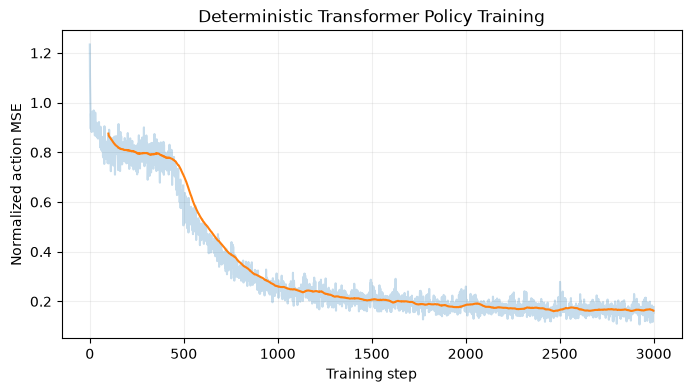

In [16]:
plt.figure(figsize=(8, 4))

plt.plot(losses, alpha=0.25)

window = 100
smoothed = np.convolve(
    losses,
    np.ones(window) / window,
    mode="valid",
)

plt.plot(
    np.arange(window - 1, len(losses)),
    smoothed,
)

plt.xlabel("Training step")
plt.ylabel("Normalized action MSE")
plt.title("Deterministic Transformer Policy Training")
plt.grid(alpha=0.2)
plt.show()

In [17]:
initial_observation = np.array([0.0, 0.0, 0.0, 1.0])

policy.eval()

obs = torch.as_tensor(
    initial_observation,
    dtype=torch.float32,
    device=device,
).reshape(1, -1)

with torch.no_grad():
    predicted = policy(obs)

# Denormalize
predicted = predicted * std + mean

predicted = predicted[0].cpu().numpy()

print("Predicted chunk:\n", predicted)

Predicted chunk:
 [[-0.00430521  0.04163084]
 [ 0.00268693  0.04034846]
 [ 0.00341088  0.04027706]
 [ 0.003737    0.03987842]
 [ 0.00377101  0.04013605]
 [ 0.00300192  0.04004866]
 [ 0.00348849  0.04017685]
 [ 0.00277734  0.04036053]]


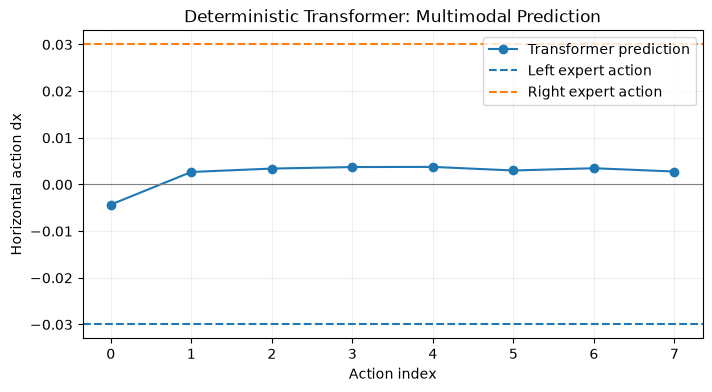

In [18]:
plt.figure(figsize=(8, 4))

plt.plot(
    predicted[:, 0],
    "o-",
    label="Transformer prediction",
)

plt.axhline(
    -0.03,
    color="tab:blue",
    linestyle="--",
    label="Left expert action",
)

plt.axhline(
    +0.03,
    color="tab:orange",
    linestyle="--",
    label="Right expert action",
)

plt.axhline(0, color="gray", linewidth=0.8)

plt.xlabel("Action index")
plt.ylabel("Horizontal action dx")
plt.title("Deterministic Transformer: Multimodal Prediction")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 4. ACT as a Conditional Variational Autoencoder

Our deterministic Transformer predicts the conditional mean of
the action chunks and fails to represent multimodal demonstrations.

ACT introduces a latent variable to represent different
action sequences.

During training, a posterior encoder estimates:

$$
q_\phi(z \mid o, A)
$$

where $o$ is the observation and $A$ is an expert action chunk.

The latent distribution is parameterized as:

$$
q_\phi(z \mid o,A)
=
\mathcal N(\mu_\phi(o,A),
\operatorname{diag}(\sigma_\phi^2(o,A)))
$$

We sample using the reparameterization trick:

$$
z = \mu + \sigma \odot \epsilon,
\qquad \epsilon \sim \mathcal N(0,I)
$$

The Transformer decoder predicts:

$$
\hat A = f_\theta(o,z)
$$

The training objective combines action reconstruction and
KL regularization:

$$
\mathcal L =
\mathcal L_{\text{reconstruction}}
+
\beta D_{\mathrm{KL}}
\left(
q_\phi(z\mid o,A)
\| \mathcal N(0,I)
\right)
$$

The original ACT uses an L1 action reconstruction loss.

At inference time, the posterior encoder is discarded.
The original ACT inference procedure uses the prior mean
$z=0$, producing a deterministic policy.

We will additionally experiment with sampling $z$ from
the prior to investigate multimodal generation.

### 4.1 Latent Encoder

In [19]:
class ACTLatentEncoder(nn.Module):
    def __init__(
        self,
        obs_dim,
        action_dim=2,
        horizon=8,
        latent_dim=8,
        hidden_dim=128,
    ):
        super().__init__()

        input_dim = obs_dim + horizon * action_dim

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )

        self.mu_head = nn.Linear(hidden_dim, latent_dim)
        self.logvar_head = nn.Linear(hidden_dim, latent_dim)

    def forward(self, observation, actions):

        B = observation.shape[0]

        flat_actions = actions.reshape(B, -1)

        x = torch.cat(
            [observation, flat_actions],
            dim=-1,
        )

        h = self.net(x)

        mu = self.mu_head(h)
        logvar = self.logvar_head(h)

        return mu, logvar

In [20]:
latent_dim = 8

latent_encoder = ACTLatentEncoder(
    obs_dim=obs_dim,
    action_dim=action_dim,
    horizon=H,
    latent_dim=latent_dim,
).to(device)

dummy_obs = torch.randn(4, obs_dim, device=device)

dummy_actions = torch.randn(
    4, H, action_dim, device=device
)

mu, logvar = latent_encoder(
    dummy_obs,
    dummy_actions,
)

print("Mean:", mu.shape)
print("Log variance:", logvar.shape)

Mean: torch.Size([4, 8])
Log variance: torch.Size([4, 8])


### 4.2 Reparameterization and KL Divergence

In [21]:
def reparameterize(mu, logvar):
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + std * eps


def kl_divergence(mu, logvar):
    kl = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return kl.sum(dim=-1).mean()

In [22]:
z = reparameterize(mu, logvar)
kl = kl_divergence(mu, logvar)

print("Latent sample:", z.shape)
print("KL divergence:", kl.item())

Latent sample: torch.Size([4, 8])
KL divergence: 0.07801234722137451


### 4.3 Mini-ACT: Conditional VAE with a Transformer Decoder

We now combine our latent encoder with the Transformer decoder.

During training, the posterior encoder receives the observation
and the expert action chunk:

$$
(\mu,\log\sigma^2)=E_\phi(o,A)
$$

We sample a latent variable:

$$
z=\mu+\sigma\odot\epsilon,
\qquad \epsilon\sim\mathcal N(0,I)
$$

The observation and latent variable are converted into context tokens.

Learned action queries attend to this context through a
Transformer decoder, producing a complete action chunk:

$$
\hat A=D_\theta(o,z)
$$

The objective is:

$$
\mathcal L=
\mathcal L_{\text{reconstruction}}
+\beta D_{\mathrm{KL}}
\left(q_\phi(z\mid o,A)\|\mathcal N(0,I)\right)
$$

We use L1 reconstruction loss, as in ACT.

At inference time, the posterior encoder is not needed.
We can use the prior mean $z=0$ or sample $z\sim\mathcal N(0,I)$.

Our implementation is a simplified Mini-ACT, not an exact
reproduction of the original ACT architecture.

In [23]:
class MiniACT(nn.Module):
    def __init__(
        self,
        obs_dim,
        action_dim=2,
        horizon=8,
        latent_dim=8,
        d_model=64,
        n_heads=4,
        n_layers=2,
    ):
        super().__init__()

        self.horizon = horizon
        self.latent_dim = latent_dim

        # CVAE posterior encoder
        self.latent_encoder = ACTLatentEncoder(
            obs_dim=obs_dim,
            action_dim=action_dim,
            horizon=horizon,
            latent_dim=latent_dim,
        )

        # Observation tokens
        self.obs_projection = nn.Linear(1, d_model)

        self.obs_pos_embedding = nn.Parameter(
            torch.randn(1, obs_dim, d_model) * 0.02
        )

        # Latent token
        self.latent_projection = nn.Linear(
            latent_dim, d_model
        )

        # Action queries
        self.action_queries = nn.Parameter(
            torch.randn(1, horizon, d_model) * 0.02
        )

        # Transformer decoder
        self.decoder = nn.ModuleList([
            TransformerDecoderBlock(
                d_model=d_model,
                n_heads=n_heads,
                dim_feedforward=4 * d_model,
            )
            for _ in range(n_layers)
        ])

        self.action_head = nn.Linear(
            d_model, action_dim
        )

    def decode(self, observation, z):
        B = observation.shape[0]

        obs_tokens = (
            self.obs_projection(observation.unsqueeze(-1))
            + self.obs_pos_embedding
        )

        latent_token = self.latent_projection(
            z
        ).unsqueeze(1)

        # Observation tokens + latent token
        context = torch.cat(
            [obs_tokens, latent_token],
            dim=1,
        )

        queries = self.action_queries.expand(
            B, -1, -1
        )

        x = queries

        for block in self.decoder:
            x = block(x, context)

        return self.action_head(x)

    def forward(self, observation, actions=None, z=None):

        if actions is not None:
            # Training: posterior q(z | o, A)
            mu, logvar = self.latent_encoder(
                observation, actions
            )

            z = reparameterize(mu, logvar)

        else:
            # Inference: prior mean unless z is supplied
            mu, logvar = None, None

            if z is None:
                z = torch.zeros(
                    observation.shape[0],
                    self.latent_dim,
                    device=observation.device,
                    dtype=observation.dtype,
                )

        predicted_actions = self.decode(
            observation, z
        )

        return predicted_actions, mu, logvar

In [24]:
mini_act = MiniACT(
    obs_dim=obs_dim,
    action_dim=action_dim,
    horizon=H,
    latent_dim=8,
).to(device)

dummy_obs = torch.randn(
    4, obs_dim, device=device
)

dummy_actions = torch.randn(
    4, H, action_dim, device=device
)

# Training
predicted, mu, logvar = mini_act(
    dummy_obs, dummy_actions
)

print("Training:")
print("Predicted:", predicted.shape)
print("Mean:", mu.shape)
print("Logvar:", logvar.shape)

# Inference
with torch.no_grad():
    predicted, _, _ = mini_act(dummy_obs)

print("\nInference:")
print("Predicted:", predicted.shape)

Training:
Predicted: torch.Size([4, 8, 2])
Mean: torch.Size([4, 8])
Logvar: torch.Size([4, 8])

Inference:
Predicted: torch.Size([4, 8, 2])


### 4.4. Training Mini-ACT

In [25]:
optimizer = torch.optim.Adam(
    mini_act.parameters(),
    lr=3e-4,
)

beta = 0.01
n_steps = 4000
batch_size = 256

reconstruction_losses = []
kl_losses = []
total_losses = []

mini_act.train()

for step_idx in range(n_steps):

    indices = torch.randint(
        len(obs_train),
        (batch_size,),
        device=device,
    )

    obs_batch = obs_train[indices]
    target_chunks = actions_train[indices]

    predicted, mu, logvar = mini_act(
        obs_batch,
        target_chunks,
    )

    reconstruction_loss = F.l1_loss(
        predicted,
        target_chunks,
    )

    kl_loss = kl_divergence(mu, logvar)

    loss = reconstruction_loss + beta * kl_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    reconstruction_losses.append(
        reconstruction_loss.item()
    )
    kl_losses.append(kl_loss.item())
    total_losses.append(loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1}/{n_steps} | "
            f"Recon: {reconstruction_loss.item():.4f} | "
            f"KL: {kl_loss.item():.4f}"
        )

Step 500/4000 | Recon: 0.2773 | KL: 3.6446
Step 1000/4000 | Recon: 0.2100 | KL: 4.5042
Step 1500/4000 | Recon: 0.1773 | KL: 4.8648
Step 2000/4000 | Recon: 0.1473 | KL: 5.1409
Step 2500/4000 | Recon: 0.1382 | KL: 5.0597
Step 3000/4000 | Recon: 0.1556 | KL: 5.1726
Step 3500/4000 | Recon: 0.1717 | KL: 5.0286
Step 4000/4000 | Recon: 0.1487 | KL: 4.9104


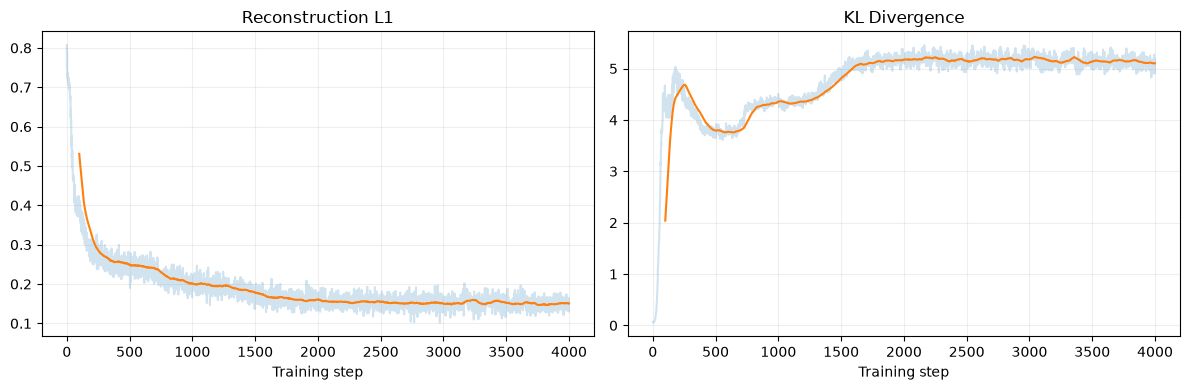

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

window = 100

for values, ax, title in [
    (reconstruction_losses, axes[0], "Reconstruction L1"),
    (kl_losses, axes[1], "KL Divergence"),
]:
    smoothed = np.convolve(
        values,
        np.ones(window) / window,
        mode="valid",
    )

    ax.plot(values, alpha=0.2)

    ax.plot(
        np.arange(window - 1, len(values)),
        smoothed,
    )

    ax.set_title(title)
    ax.set_xlabel("Training step")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 4.5 Latent Sampling and Multimodality

We trained Mini-ACT using a CVAE latent encoder and a
Transformer action decoder.

The reconstruction loss decreased, while the KL divergence
remained positive.

We now investigate whether the latent variable controls
the generated action strategy.

We fix the initial observation:

$$
o = [0,0,0,1]
$$

and sample latent variables from the prior:

$$
z \sim \mathcal N(0,I)
$$

For each latent sample, the Transformer decoder generates
a complete action chunk:

$$
\hat A = D_\theta(o,z)
$$

We inspect the first action distribution and compare it
with the deterministic prediction obtained using $z=0$.

In [27]:
mini_act.eval()

n_samples = 500

obs = torch.as_tensor(
    initial_observation,
    dtype=torch.float32,
    device=device,
).reshape(1, -1)

obs_batch = obs.expand(n_samples, -1)

with torch.no_grad():

    # Sample from the prior
    z = torch.randn(
        n_samples,
        mini_act.latent_dim,
        device=device,
    )

    sampled_chunks, _, _ = mini_act(
        obs_batch,
        z=z,
    )

    # Prior mean (original ACT inference strategy)
    zero_chunks, _, _ = mini_act(
        obs,
    )

    # Denormalize
    sampled_chunks = sampled_chunks * std + mean
    zero_chunks = zero_chunks * std + mean

sampled_chunks = sampled_chunks.cpu().numpy()
zero_chunk = zero_chunks[0].cpu().numpy()

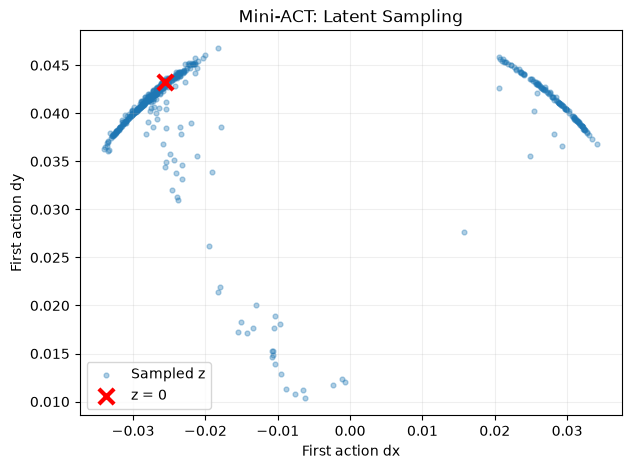

In [28]:
first_actions = sampled_chunks[:, 0, :]

plt.figure(figsize=(7, 5))

plt.scatter(
    first_actions[:, 0],
    first_actions[:, 1],
    alpha=0.35,
    s=12,
    label="Sampled z",
)

plt.scatter(
    zero_chunk[0, 0],
    zero_chunk[0, 1],
    color="red",
    marker="x",
    s=120,
    linewidths=3,
    label="z = 0",
)

plt.xlabel("First action dx")
plt.ylabel("First action dy")
plt.title("Mini-ACT: Latent Sampling")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 5. Transformer Latent Encoder

Our first Mini-ACT used an MLP to encode the observation and
expert action chunk into a latent distribution.

The original ACT architecture instead uses a Transformer encoder.

The input sequence contains:

- A learnable CLS token.
- A robot state token.
- One token for each expert action.

Positional embeddings identify the positions in the sequence.

The Transformer encoder applies self-attention across all tokens.

The final CLS representation summarizes information from
the observation and the demonstrated action sequence.

Two linear heads produce the parameters of the approximate
posterior distribution:

$$
q_\phi(z\mid o,A)
=
\mathcal N(\mu_\phi,\operatorname{diag}(\sigma_\phi^2))
$$

The reparameterization trick and KL divergence remain unchanged.

We will replace the MLP latent encoder with a Transformer encoder,
keeping the action decoder and training objective unchanged.

In [29]:
class TransformerLatentEncoder(nn.Module):
    def __init__(
        self,
        obs_dim,
        action_dim=2,
        horizon=8,
        latent_dim=8,
        d_model=64,
        n_heads=4,
        n_layers=2,
    ):
        super().__init__()

        # Token embeddings
        self.obs_projection = nn.Linear(obs_dim, d_model)
        self.action_projection = nn.Linear(action_dim, d_model)

        # Special CLS token
        self.cls_token = nn.Parameter(
            torch.randn(1, 1, d_model) * 0.02
        )

        # CLS + observation + H actions
        self.pos_embedding = nn.Parameter(
            torch.randn(1, horizon + 2, d_model) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=4 * d_model,
            dropout=0.0,
            batch_first=True,
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers,
        )

        self.mu_head = nn.Linear(d_model, latent_dim)
        self.logvar_head = nn.Linear(d_model, latent_dim)

    def forward(self, observation, actions):
        B = observation.shape[0]

        cls = self.cls_token.expand(B, -1, -1)

        obs_token = self.obs_projection(
            observation
        ).unsqueeze(1)

        action_tokens = self.action_projection(actions)

        # (B, H+2, d_model)
        tokens = torch.cat(
            [cls, obs_token, action_tokens],
            dim=1,
        )

        tokens = tokens + self.pos_embedding

        encoded = self.encoder(tokens)

        # Extract CLS representation
        cls_output = encoded[:, 0, :]

        mu = self.mu_head(cls_output)
        logvar = self.logvar_head(cls_output)

        return mu, logvar

In [30]:
transformer_latent_encoder = TransformerLatentEncoder(
    obs_dim=obs_dim,
    action_dim=action_dim,
    horizon=H,
    latent_dim=8,
).to(device)

dummy_obs = torch.randn(
    4, obs_dim, device=device
)

dummy_actions = torch.randn(
    4, H, action_dim, device=device
)

mu, logvar = transformer_latent_encoder(
    dummy_obs,
    dummy_actions,
)

print("Mean:", mu.shape)
print("Log variance:", logvar.shape)

Mean: torch.Size([4, 8])
Log variance: torch.Size([4, 8])


New istance of MiniACT, just replacing the encoder with the Transfomer

In [31]:
mini_act_transformer = MiniACT(
    obs_dim=obs_dim,
    action_dim=action_dim,
    horizon=H,
    latent_dim=8,
).to(device)

mini_act_transformer.latent_encoder = TransformerLatentEncoder(
    obs_dim=obs_dim,
    action_dim=action_dim,
    horizon=H,
    latent_dim=8,
).to(device)

### Training

In [32]:
optimizer = torch.optim.Adam(
    mini_act_transformer.parameters(),
    lr=3e-4,
)

beta = 0.01
n_steps = 4000
batch_size = 256

transformer_recon_losses = []
transformer_kl_losses = []

mini_act_transformer.train()

for step_idx in range(n_steps):

    indices = torch.randint(
        len(obs_train),
        (batch_size,),
        device=device,
    )

    obs_batch = obs_train[indices]
    target_chunks = actions_train[indices]

    predicted, mu, logvar = mini_act_transformer(
        obs_batch,
        target_chunks,
    )

    recon_loss = F.l1_loss(
        predicted,
        target_chunks,
    )

    kl_loss = kl_divergence(mu, logvar)

    loss = recon_loss + beta * kl_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    transformer_recon_losses.append(recon_loss.item())
    transformer_kl_losses.append(kl_loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1}/{n_steps} | "
            f"Recon: {recon_loss.item():.4f} | "
            f"KL: {kl_loss.item():.4f}"
        )

Step 500/4000 | Recon: 0.2211 | KL: 4.8204
Step 1000/4000 | Recon: 0.2093 | KL: 3.9333
Step 1500/4000 | Recon: 0.1589 | KL: 4.6519
Step 2000/4000 | Recon: 0.0857 | KL: 5.3559
Step 2500/4000 | Recon: 0.0758 | KL: 5.5218
Step 3000/4000 | Recon: 0.0607 | KL: 5.5044
Step 3500/4000 | Recon: 0.0615 | KL: 5.4962
Step 4000/4000 | Recon: 0.0541 | KL: 5.6982


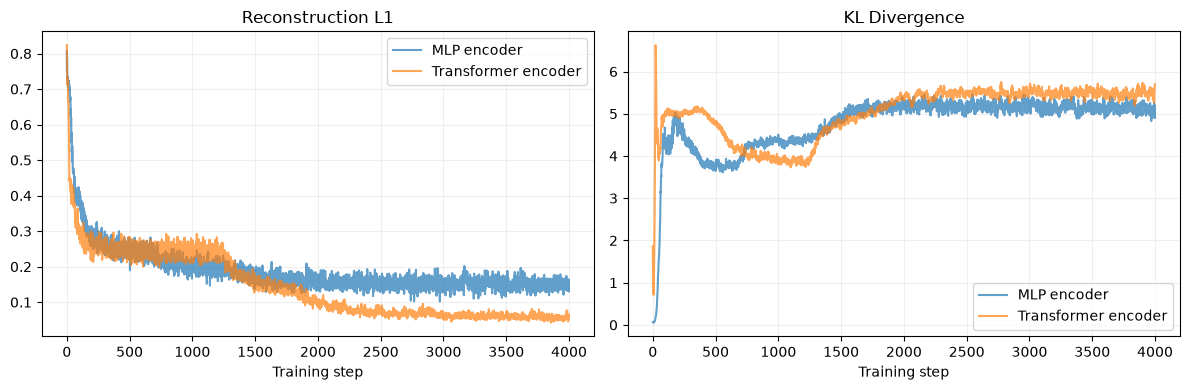

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    reconstruction_losses,
    alpha=0.7,
    label="MLP encoder",
)

axes[0].plot(
    transformer_recon_losses,
    alpha=0.7,
    label="Transformer encoder",
)

axes[0].set_title("Reconstruction L1")
axes[0].set_xlabel("Training step")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(
    kl_losses,
    alpha=0.7,
    label="MLP encoder",
)

axes[1].plot(
    transformer_kl_losses,
    alpha=0.7,
    label="Transformer encoder",
)

axes[1].set_title("KL Divergence")
axes[1].set_xlabel("Training step")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Prior Sampling with the Transformer Latent Encoder

The Transformer latent encoder achieved a lower reconstruction
loss than the MLP encoder.

However, reconstruction quality alone does not guarantee
good samples from the prior.

We now compare the action distributions generated by both
Mini-ACT variants using:

$$
z \sim \mathcal N(0,I)
$$

The observation is fixed to the initial PointRobot state.

We investigate whether both models preserve the two
left/right strategies.

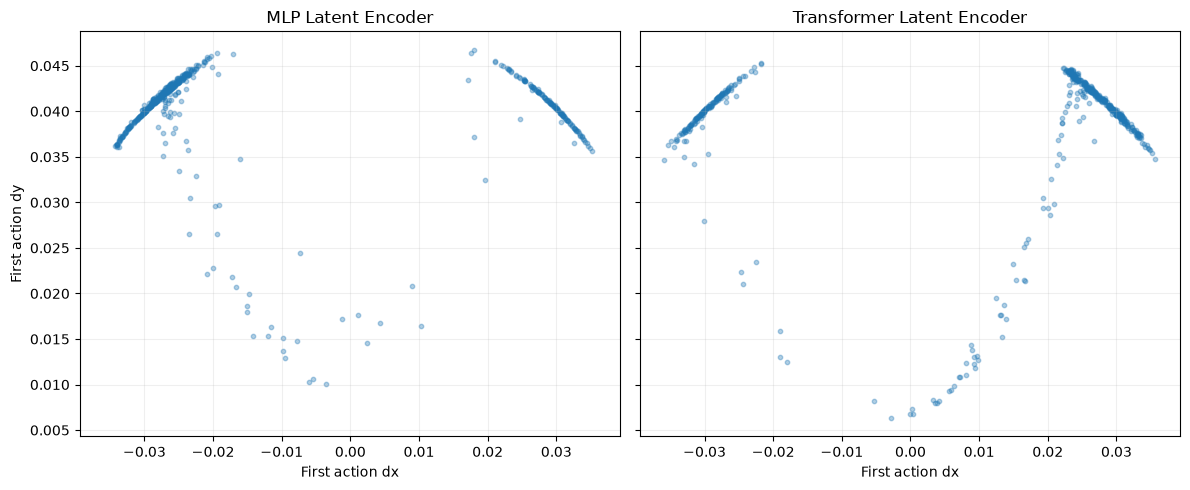

In [35]:
@torch.no_grad()
def sample_mini_act(model, observation, n_samples=500):
    model.eval()

    obs = torch.as_tensor(
        observation,
        dtype=torch.float32,
        device=device,
    ).reshape(1, -1)

    obs = obs.expand(n_samples, -1)

    z = torch.randn(
        n_samples,
        model.latent_dim,
        device=device,
    )

    chunks, _, _ = model(obs, z=z)

    chunks = chunks * std + mean

    return chunks.cpu().numpy()


# Use identical latent samples for a fairer comparison
torch.manual_seed(42)

chunks_mlp = sample_mini_act(
    mini_act,
    initial_observation,
)

torch.manual_seed(42)

chunks_transformer = sample_mini_act(
    mini_act_transformer,
    initial_observation,
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
)

for ax, chunks, title in [
    (axes[0], chunks_mlp, "MLP Latent Encoder"),
    (axes[1], chunks_transformer, "Transformer Latent Encoder"),
]:
    first_actions = chunks[:, 0, :]

    ax.scatter(
        first_actions[:, 0],
        first_actions[:, 1],
        s=10,
        alpha=0.35,
    )

    ax.set_title(title)
    ax.set_xlabel("First action dx")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("First action dy")

plt.tight_layout()
plt.show()

## 6. Temporal Ensembling

ACT predicts an action chunk at every control timestep.

Since chunks overlap in time, multiple predictions may be
available for the same future action.

Temporal ensembling combines these predictions using a
weighted average:

$$
a_t =
\frac{
\sum_{i \in \mathcal I_t} w_i \hat a_t^{(i)}
}{
\sum_{i \in \mathcal I_t} w_i
}
$$

where $\mathcal I_t$ contains the previous prediction times
whose chunks include timestep $t$.

We use exponential weights:

$$
w_i = \exp(-k(t-i))
$$

With this convention, more recent predictions receive larger
weights.

Temporal ensembling can reduce abrupt changes between
consecutive action chunks.

However, averaging predictions from different strategies may
produce undesirable intermediate actions.

In [36]:
def temporal_ensemble(chunks, current_t, k=0.1):
    """
    chunks: list of (prediction_time, chunk)
    current_t: timestep whose action must be executed
    """

    predictions = []
    ages = []

    for prediction_t, chunk in chunks:
        offset = current_t - prediction_t

        if 0 <= offset < len(chunk):
            predictions.append(chunk[offset])
            ages.append(offset)

    if not predictions:
        raise ValueError("No predictions for current timestep")

    predictions = np.stack(predictions)
    ages = np.asarray(ages)

    weights = np.exp(-k * ages)
    weights = weights / weights.sum()

    return np.sum(
        predictions * weights[:, None],
        axis=0,
    )

In [37]:
H = 4

chunk_0 = np.array([
    [-0.030, 0.04],
    [-0.030, 0.04],
    [-0.030, 0.04],
    [-0.030, 0.04],
])

chunk_1 = np.array([
    [-0.025, 0.04],
    [-0.025, 0.04],
    [-0.025, 0.04],
    [-0.025, 0.04],
])

chunk_2 = np.array([
    [-0.020, 0.04],
    [-0.020, 0.04],
    [-0.020, 0.04],
    [-0.020, 0.04],
])

history = [
    (0, chunk_0),
    (1, chunk_1),
    (2, chunk_2),
]

action = temporal_ensemble(
    history,
    current_t=2,
    k=0.5,
)

print("Ensembled action:", action)

Ensembled action: [-0.02339922  0.04      ]


In [38]:
chunk_2_right = np.array([
    [+0.030, 0.04],
    [+0.030, 0.04],
    [+0.030, 0.04],
    [+0.030, 0.04],
])

history_conflict = [
    (0, chunk_0),
    (1, chunk_1),
    (2, chunk_2_right),
]

action_conflict = temporal_ensemble(
    history_conflict,
    current_t=2,
    k=0.5,
)

print("Conflicting strategies:", action_conflict)

Conflicting strategies: [0.0019248 0.04     ]


### Closed-Loop Temporal Ensembling

We now evaluate temporal ensembling in the PointRobot environment.

We compare three execution strategies:

1. Replanning every timestep (E=1).
2. Executing complete chunks (E=8).
3. Replanning every timestep with temporal ensembling.

We use the same trained Mini-ACT model and the deterministic
prior mean:

$$
z = \mathbf{0}
$$

Temporal ensembling combines overlapping action predictions
using exponentially decaying weights.

We evaluate success rate, collision rate, timeout rate,
and the number of policy calls.

Since the policy is deterministic and the environment is
deterministic, repeated rollouts from the same initial state
will produce identical trajectories.

Therefore, we first inspect one rollout per strategy.

In [49]:
from robot_learning_playground.point_robot import make_observation, is_collision

start = np.array([0.0, 0.0])
goal = np.array([0.0, 1.0])

initial_observation = make_observation(
    start,
    goal,
)

In [50]:
@torch.no_grad()
def predict_act_chunk(model, observation):
    model.eval()

    obs = torch.as_tensor(
        observation,
        dtype=torch.float32,
        device=device,
    ).reshape(1, -1)

    # z = 0 by default
    predicted, _, _ = model(obs)

    predicted = predicted * std + mean

    return predicted[0].cpu().numpy()

In [51]:
def rollout_act_chunk(
    model,
    start,
    goal,
    execution_horizon=1,
    max_steps=100,
    goal_tolerance=0.05,
):
    position = np.asarray(start, dtype=float).copy()
    goal = np.asarray(goal, dtype=float)

    positions = [position.copy()]
    actions = []
    policy_calls = 0

    success = False
    collision = False

    while len(actions) < max_steps:

        observation = make_observation(position, goal)

        chunk = predict_act_chunk(model, observation)
        policy_calls += 1

        for action in chunk[:execution_horizon]:

            if len(actions) >= max_steps:
                break

            position = np.asarray(
                step(position, action),
                dtype=float,
            ).copy()

            positions.append(position.copy())
            actions.append(action.copy())

            if is_collision(position):
                collision = True
                break

            if np.linalg.norm(position - goal) < goal_tolerance:
                success = True
                break

        if success or collision:
            break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions),
        "success": success,
        "collision": collision,
        "policy_calls": policy_calls,
    }

In [52]:
def rollout_act_ensemble(
    model,
    start,
    goal,
    k=0.1,
    max_steps=100,
    goal_tolerance=0.05,
):
    position = np.asarray(start, dtype=float).copy()
    goal = np.asarray(goal, dtype=float)

    positions = [position.copy()]
    actions = []
    history = []

    success = False
    collision = False
    policy_calls = 0

    for t in range(max_steps):

        observation = make_observation(position, goal)

        chunk = predict_act_chunk(model, observation)

        history.append((t, chunk))
        policy_calls += 1

        # Keep only chunks that can still predict time t
        history = [
            (prediction_t, c)
            for prediction_t, c in history
            if t - prediction_t < len(c)
        ]

        action = temporal_ensemble(
            history,
            current_t=t,
            k=k,
        )

        position = np.asarray(
            step(position, action),
            dtype=float,
        ).copy()

        positions.append(position.copy())
        actions.append(action.copy())

        if is_collision(position):
            collision = True
            break

        if np.linalg.norm(position - goal) < goal_tolerance:
            success = True
            break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions),
        "success": success,
        "collision": collision,
        "policy_calls": policy_calls,
    }

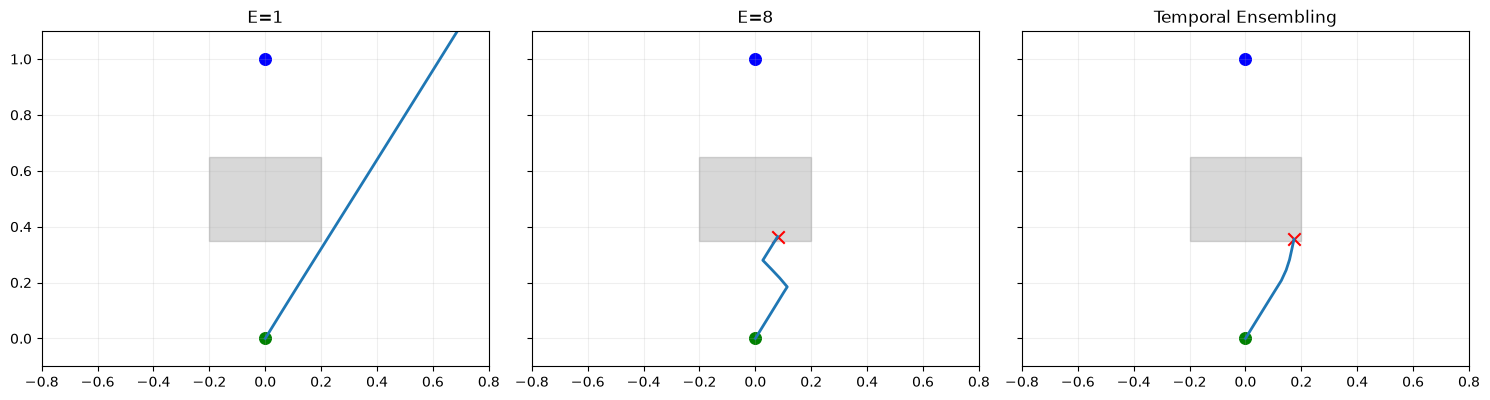

In [53]:
from matplotlib.patches import Rectangle

rollouts = {
    "E=1": rollout_act_chunk(
        mini_act_transformer,
        start,
        goal,
        execution_horizon=1,
    ),
    "E=8": rollout_act_chunk(
        mini_act_transformer,
        start,
        goal,
        execution_horizon=8,
    ),
    "Temporal Ensembling": rollout_act_ensemble(
        mini_act_transformer,
        start,
        goal,
        k=0.1,
    ),
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True,
)

for ax, (name, result) in zip(axes, rollouts.items()):

    positions = result["positions"]

    ax.add_patch(
        Rectangle(
            (-0.2, 0.35),
            0.4,
            0.3,
            color="gray",
            alpha=0.3,
        )
    )

    ax.plot(
        positions[:, 0],
        positions[:, 1],
        linewidth=2,
    )

    ax.scatter(*start, color="green", s=70)
    ax.scatter(*goal, color="blue", s=70)

    if result["collision"]:
        ax.scatter(
            *positions[-1],
            color="red",
            marker="x",
            s=80,
        )

    ax.set_title(name)
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [54]:
for name, result in rollouts.items():

    timeout = (
        not result["success"]
        and not result["collision"]
    )

    print(
        f"{name:20s} | "
        f"Success: {result['success']} | "
        f"Collision: {result['collision']} | "
        f"Timeout: {timeout} | "
        f"Steps: {len(result['actions'])} | "
        f"Policy calls: {result['policy_calls']}"
    )

E=1                  | Success: False | Collision: False | Timeout: True | Steps: 100 | Policy calls: 100
E=8                  | Success: False | Collision: True | Timeout: False | Steps: 10 | Policy calls: 2
Temporal Ensembling  | Success: False | Collision: True | Timeout: False | Steps: 9 | Policy calls: 9


### Diagnosing ACT Action Chunks

Our deterministic Mini-ACT rollouts failed despite successful
multimodal prior sampling.

We now inspect complete action chunks rather than only their
first actions.

We compare:

- The deterministic prior mean, $z=\mathbf{0}$.
- Random latent vectors sampled from the prior.

We investigate whether each generated chunk maintains a
consistent horizontal direction across its prediction horizon.

This helps distinguish within-chunk inconsistency from
inconsistency between consecutive replanning steps.

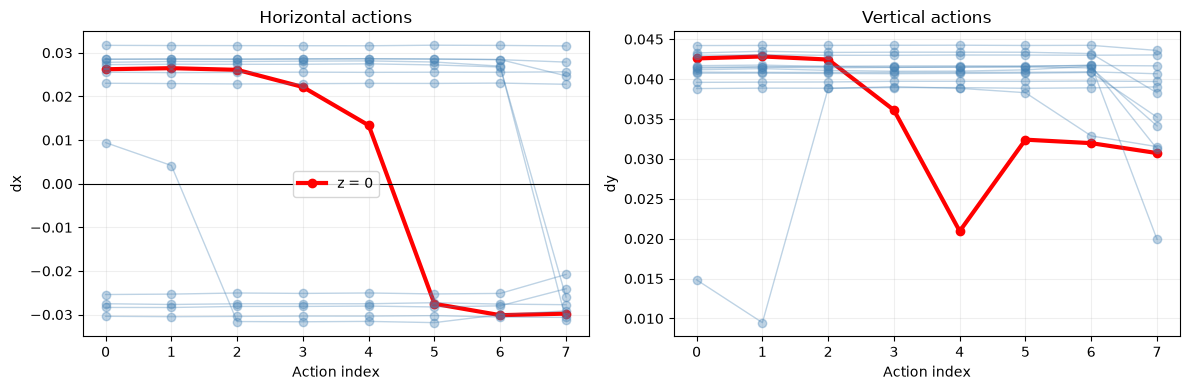

In [55]:
mini_act_transformer.eval()

obs = torch.as_tensor(
    initial_observation,
    dtype=torch.float32,
    device=device,
).reshape(1, -1)

n_random = 12

with torch.no_grad():
    z_random = torch.randn(
        n_random,
        mini_act_transformer.latent_dim,
        device=device,
    )

    z_zero = torch.zeros(
        1,
        mini_act_transformer.latent_dim,
        device=device,
    )

    z_all = torch.cat([z_zero, z_random], dim=0)
    obs_all = obs.expand(len(z_all), -1)

    chunks, _, _ = mini_act_transformer(
        obs_all,
        z=z_all,
    )

    chunks = chunks * std + mean
    chunks = chunks.cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, chunk in enumerate(chunks):
    label = "z = 0" if i == 0 else None

    axes[0].plot(
        chunk[:, 0],
        "o-",
        color="red" if i == 0 else "steelblue",
        linewidth=3 if i == 0 else 1,
        alpha=1 if i == 0 else 0.35,
        label=label,
    )

    axes[1].plot(
        chunk[:, 1],
        "o-",
        color="red" if i == 0 else "steelblue",
        linewidth=3 if i == 0 else 1,
        alpha=1 if i == 0 else 0.35,
    )

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Horizontal actions")
axes[0].set_ylabel("dx")
axes[0].legend()

axes[1].set_title("Vertical actions")
axes[1].set_ylabel("dy")

for ax in axes:
    ax.set_xlabel("Action index")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

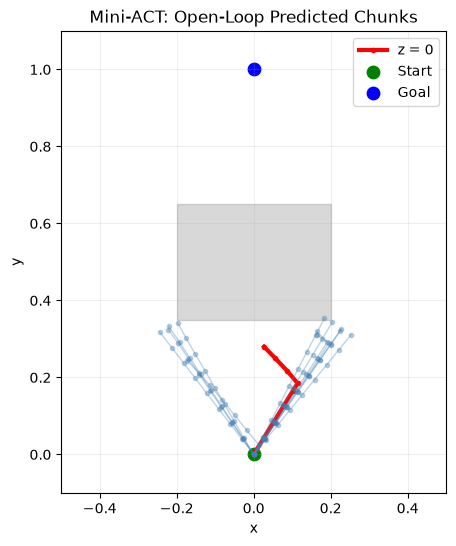

In [56]:
from matplotlib.patches import Rectangle

start_position = np.asarray(start, dtype=float)

fig, ax = plt.subplots(figsize=(7, 6))

ax.add_patch(
    Rectangle(
        (-0.2, 0.35),
        0.4,
        0.3,
        color="gray",
        alpha=0.3,
    )
)

for i, chunk in enumerate(chunks):

    positions = np.vstack([
        start_position,
        start_position + np.cumsum(chunk, axis=0),
    ])

    ax.plot(
        positions[:, 0],
        positions[:, 1],
        "o-",
        color="red" if i == 0 else "steelblue",
        linewidth=3 if i == 0 else 1,
        alpha=1 if i == 0 else 0.35,
        markersize=3,
        label="z = 0" if i == 0 else None,
    )

ax.scatter(*start, color="green", s=80, label="Start")
ax.scatter(*goal, color="blue", s=80, label="Goal")

ax.set_xlim(-0.5, 0.5)
ax.set_ylim(-0.1, 1.1)
ax.set_aspect("equal")
ax.set_title("Mini-ACT: Open-Loop Predicted Chunks")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

### Fixed Latent Rollouts

Our Mini-ACT generates multimodal action chunks when sampling
latent vectors from the prior.

However, the deterministic prior mean $z=\mathbf{0}$ produces
an undesirable initial chunk.

We now sample a latent vector once per episode:

$$
z_{\text{episode}}\sim\mathcal N(0,I)
$$

and keep it fixed during the entire rollout.

At each replanning step:

$$
\hat A_t=D_\theta(o_t,z_{\text{episode}})
$$

We execute the first $E$ actions and then replan.

This experiment investigates whether a fixed latent variable
helps maintain a coherent strategy across action chunks.

In [57]:
@torch.no_grad()
def predict_act_chunk_with_z(model, observation, z):
    model.eval()

    obs = torch.as_tensor(
        observation, dtype=torch.float32, device=device
    ).reshape(1, -1)

    predicted, _, _ = model(obs, z=z)

    return (predicted * std + mean)[0].cpu().numpy()


def rollout_act_fixed_z(
    model, start, goal, z,
    execution_horizon=8,
    max_steps=100,
    goal_tolerance=0.05,
):
    position = np.asarray(start, dtype=float).copy()
    goal = np.asarray(goal, dtype=float)

    positions = [position.copy()]
    actions = []
    policy_calls = 0
    success = collision = False

    while len(actions) < max_steps:
        observation = make_observation(position, goal)
        chunk = predict_act_chunk_with_z(model, observation, z)
        policy_calls += 1

        for action in chunk[:execution_horizon]:
            if len(actions) >= max_steps:
                break

            position = np.asarray(
                step(position, action), dtype=float
            ).copy()

            positions.append(position.copy())
            actions.append(action.copy())

            if is_collision(position):
                collision = True
                break

            if np.linalg.norm(position - goal) < goal_tolerance:
                success = True
                break

        if success or collision:
            break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions),
        "success": success,
        "collision": collision,
        "policy_calls": policy_calls,
    }

In [58]:
n_episodes = 30
results = []

for _ in range(n_episodes):
    z = torch.randn(
        1, mini_act_transformer.latent_dim,
        device=device,
    )

    result = rollout_act_fixed_z(
        mini_act_transformer,
        start,
        goal,
        z,
        execution_horizon=8,
    )

    results.append(result)

success_rate = np.mean([r["success"] for r in results])
collision_rate = np.mean([r["collision"] for r in results])
timeout_rate = 1 - success_rate - collision_rate

print(f"Success:   {success_rate:.1%}")
print(f"Collision: {collision_rate:.1%}")
print(f"Timeout:   {timeout_rate:.1%}")

Success:   0.0%
Collision: 20.0%
Timeout:   80.0%


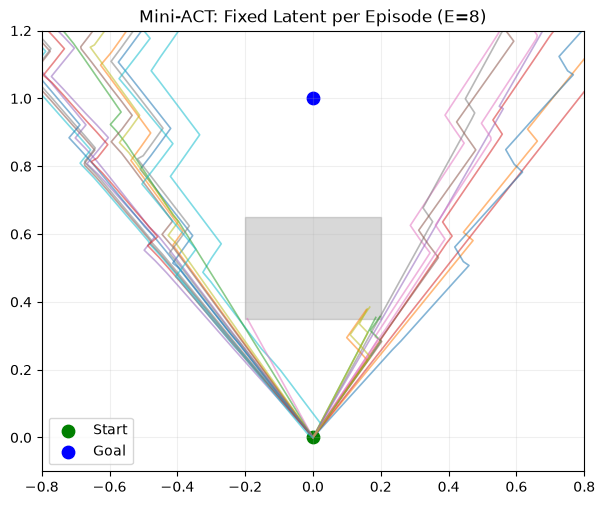

In [59]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.add_patch(
    Rectangle(
        (-0.2, 0.35), 0.4, 0.3,
        color="gray", alpha=0.3,
    )
)

for result in results:
    p = result["positions"]

    ax.plot(
        p[:, 0], p[:, 1],
        alpha=0.55,
        linewidth=1.2,
    )

ax.scatter(*start, color="green", s=80, label="Start")
ax.scatter(*goal, color="blue", s=80, label="Goal")

ax.set_xlim(-0.8, 0.8)
ax.set_ylim(-0.1, 1.2)
ax.set_aspect("equal")
ax.set_title("Mini-ACT: Fixed Latent per Episode (E=8)")
ax.legend()
ax.grid(alpha=0.2)

plt.show()